# Câu 3: Khảo sát sự liên quan giữa Độ tuổi (age), Giới tính (sex) và khả năng sống sót (survived)

Phần 1 – Bài 2 (trang 15–17): Yêu cầu lập trình trên dữ liệu Titanic

In [6]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [7]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [8]:
df = pd.read_csv(DATA + 'titanic.csv', dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

---
## Thực hiện yêu cầu

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


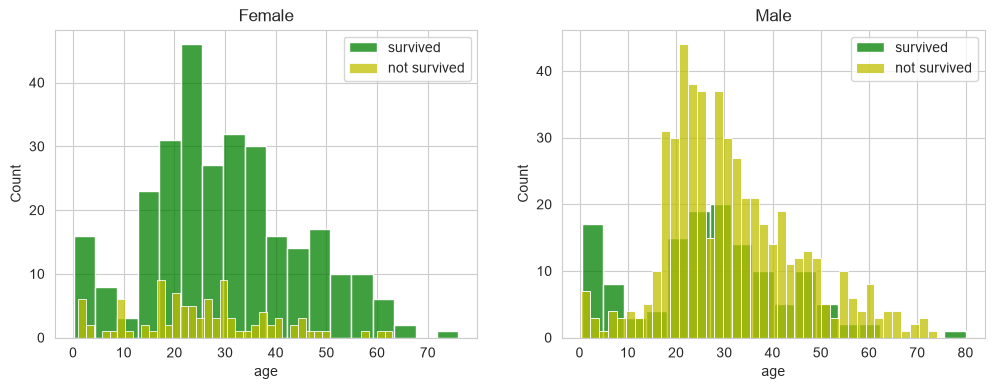

In [9]:
print(SV)
survived, not_survived = 'survived', 'not survived'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']
for ax, data, name in [(axes[0], women, 'Female'), (axes[1], men, 'Male')]:
    sns.histplot(data[data['survived'] == 1]['age'].dropna(), bins=18, label=survived, ax=ax, color='g')
    sns.histplot(data[data['survived'] == 0]['age'].dropna(), bins=40, label=not_survived, ax=ax, color='y')
    ax.legend()
    ax.set_title(name)
plt.show()

Tỷ lệ sống sót theo giới tính và theo nhóm tuổi:

In [10]:
age_group = pd.cut(df['age'], bins=[0, 10, 18, 27, 40, 60, 81])
pd.crosstab(age_group, df['sex'], values=df['survived'], aggfunc='mean').round(2)

sex,female,male
age,,
"(0, 10]",0.61,0.56
"(10, 18]",0.75,0.12
"(18, 27]",0.73,0.19
"(27, 40]",0.77,0.19
"(40, 60]",0.83,0.19
"(60, 81]",0.86,0.08


In [11]:
df.groupby('sex')['survived'].agg(['count', 'mean']).round(3)

,count,mean
sex,,
female,466,0.727
male,843,0.191


**Nhận xét:**

- Nữ có tỷ lệ sống sót vượt trội: 72,7% so với 19,1% ở nam; ở mọi nhóm tuổi nữ đều sống sót nhiều hơn nam.
- Với nam, chỉ nhóm trẻ em 0–10 tuổi có tỷ lệ sống sót cao (≈56%); từ 11 tuổi trở lên tỷ lệ giảm hẳn xuống ≈12–19%, và trên 60 tuổi chỉ còn ≈8%.
- Nam từ khoảng 18 đến 35 tuổi có số người không sống sót đông nhất (cột vàng cao nhất trên biểu đồ).
- Với nữ, tỷ lệ sống sót cao ở mọi độ tuổi (≈61–86%) và thậm chí tăng theo tuổi; số nữ sống sót tập trung nhiều ở 15–40 tuổi.
- Điều này phù hợp với nguyên tắc "phụ nữ và trẻ em trước" khi lên xuồng cứu sinh.